# Streaming decision-tree demonstration

From the project root, install the package with `python -m pip install -e ".[visualization]"` and the notebook tools with `python -m pip install ipython ipykernel`. Open this notebook, select that environment, restart the kernel, and choose **Run All**. The working directory can be the project root or `demo/`.

This end-to-end example loads `demo/data/sample.csv` with NumCompute, prepares ordered train and holdout rows, feeds training chunks through `Pipeline.partial_fit()` via `StreamTrainer`, tracks chunk and cumulative holdout metrics, compares two tree buffer sizes, and displays predictions for the latest holdout chunk. Incomplete rows are removed because the decision tree requires finite numeric features. The pipeline uses raw features intentionally: an online scaler changes its coordinate system after each chunk, which would make buffered tree retraining mix differently scaled rows.

The holdout is the final 30% of the CSV by row order; it is not used for training. The CSV is loaded into memory before chunked processing, so this is a streaming simulation rather than a bounded-memory CSV reader.

In [26]:
import sys
from pathlib import Path
import numpy as np

root = Path.cwd() if (Path.cwd() / "numcompute").is_dir() else Path.cwd().parent
sys.path.insert(0, str(root))
from numcompute import io

sample_path = root / "demo" / "data" / "sample.csv"
X_num = io.load_csv(sample_path, usecols=["age", "income"], dtype=float)
city = io.load_csv(sample_path, usecols="city")
np.set_printoptions(precision=3, suppress=True)

In [27]:
from numcompute.pipeline import Pipeline
from numcompute_stream.stream import StreamTrainer
from numcompute_stream.tree import DecisionTreeClassifier
from numcompute.metrics import StreamingMetrics

stream_X = X_num
stream_y = city.ravel()
split_at = int(0.7 * len(stream_y))
row_index = np.arange(len(stream_y))
complete = np.isfinite(stream_X).all(axis=1) & (stream_y != "")
train_rows = complete & (row_index < split_at)
test_rows = complete & (row_index >= split_at)
X_stream_train, y_stream_train = stream_X[train_rows], stream_y[train_rows]
X_stream_test, y_stream_test = stream_X[test_rows], stream_y[test_rows]
stream_chunk_size = 250

print("Complete training rows:", len(y_stream_train))
print("Complete holdout rows:", len(y_stream_test))
print("Classes:", np.unique(stream_y[complete]))

Complete training rows: 1745
Complete holdout rows: 780
Classes: ['Adelaide' 'Brisbane' 'Hobart' 'Melbourne' 'Perth' 'Sydney']


## 1. Train models chunk by chunk

Both pipelines call the tree's buffered `partial_fit()`. A retrain happens after the accumulated buffer reaches `buffer_size`; chunks may cross that threshold, so the exact retrain batch can be larger than the threshold. Compare a smaller and larger buffer to see their effects on the holdout stream.

In [28]:
tree_small_buffer = DecisionTreeClassifier(max_depth=6, buffer_size=300, random_state=0)
tree_large_buffer = DecisionTreeClassifier(max_depth=6, buffer_size=600, random_state=0)
pipe_small_buffer = Pipeline([("tree", tree_small_buffer)])
pipe_large_buffer = Pipeline([("tree", tree_large_buffer)])
trainer_small_buffer = StreamTrainer(tree_small_buffer, pipeline=pipe_small_buffer)
trainer_large_buffer = StreamTrainer(tree_large_buffer, pipeline=pipe_large_buffer)

for start in range(0, len(X_stream_train), stream_chunk_size):
    X_chunk = X_stream_train[start : start + stream_chunk_size]
    y_chunk = y_stream_train[start : start + stream_chunk_size]
    trainer_small_buffer.fit_chunk(X_chunk, y_chunk)
    trainer_large_buffer.fit_chunk(X_chunk, y_chunk) 

print("Training chunks:", len(trainer_small_buffer.history))
print("Tree buffer sizes:", tree_small_buffer.buffer_size, "and", tree_large_buffer.buffer_size)

Training chunks: 7
Tree buffer sizes: 300 and 600


## 2. Evaluate each holdout chunk

`StreamTrainer.score_chunk()` records per-chunk accuracy and cumulative counts. `StreamingMetrics` independently accumulates macro precision, recall, F1, and confusion matrices, plus rolling metrics over the latest 400 samples. Decision trees return class labels rather than probability scores, so this demonstration does not calculate AUC.

In [29]:
known_classes = np.unique(stream_y[complete])
metrics_small_buffer = StreamingMetrics(average="macro", labels=known_classes, window_size=400)
metrics_large_buffer = StreamingMetrics(average="macro", labels=known_classes, window_size=400)
small_chunk_accuracy, large_chunk_accuracy = [], []
small_cumulative_accuracy, large_cumulative_accuracy = [], []
test_chunk_numbers = []
latest_X, latest_y_true, latest_y_pred = None, None, None

for chunk_number, start in enumerate(range(0, len(X_stream_test), stream_chunk_size), start=1):
    X_chunk = X_stream_test[start : start + stream_chunk_size]
    y_chunk = y_stream_test[start : start + stream_chunk_size]
    small_score = trainer_small_buffer.score_chunk(X_chunk, y_chunk)
    large_score = trainer_large_buffer.score_chunk(X_chunk, y_chunk)
    pred_small = pipe_small_buffer.predict(X_chunk)
    pred_large = pipe_large_buffer.predict(X_chunk)
    metrics_small_buffer.update(y_chunk, pred_small)
    metrics_large_buffer.update(y_chunk, pred_large)

    small_chunk_accuracy.append(small_score)
    large_chunk_accuracy.append(large_score)
    small_cumulative_accuracy.append(metrics_small_buffer.result()["accuracy"])
    large_cumulative_accuracy.append(metrics_large_buffer.result()["accuracy"])
    test_chunk_numbers.append(chunk_number)
    latest_X, latest_y_true, latest_y_pred = X_chunk, y_chunk, pred_small

small_result = metrics_small_buffer.result()
large_result = metrics_large_buffer.result()
print(f"Small-buffer holdout accuracy: {small_result['accuracy']:.3f}; macro F1: {small_result['f1']:.3f}")
print(f"Large-buffer holdout accuracy: {large_result['accuracy']:.3f}; macro F1: {large_result['f1']:.3f}")
print("Small-buffer confusion matrix (rows=true, columns=predicted):\n", small_result["confusion_matrix"])
print("Small-buffer accuracy on latest 400 rows:", f"{metrics_small_buffer.rolling_result()['accuracy']:.3f}")

history = trainer_small_buffer.get_history()
print("First training entry:", history[0])
print("Latest scoring entry:", history[-1])

Small-buffer holdout accuracy: 0.765; macro F1: 0.765
Large-buffer holdout accuracy: 0.759; macro F1: 0.758
Small-buffer confusion matrix (rows=true, columns=predicted):
 [[ 96  26   0   5   0   0]
 [ 19  89  10   3   1   0]
 [  2  23 113   0   1   0]
 [  6  10   0  77  11   9]
 [  0  14   0  13 104  15]
 [  0   0   0  10   5 118]]
Small-buffer accuracy on latest 400 rows: 0.770
First training entry: {'chunk_index': 0, 'samples': 250, 'memory_mb': 0.0, 'peak_memory_mb': 0.01264190673828125}
Latest scoring entry: {'chunk_index': 10, 'samples': 30, 'accuracy': 0.7666666666666667, 'cumulative_accuracy': 0.7653846153846153, 'memory_mb': 0.0}


## 3. Plot the stream and inspect the latest predictions

The first plot compares per-chunk holdout accuracy for the two buffer sizes. The second shows cumulative accuracy for the smaller-buffer tree. The final plot compares actual and predicted labels from the latest holdout chunk.

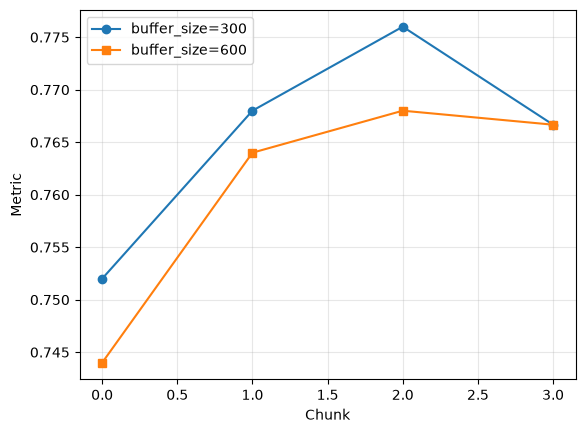

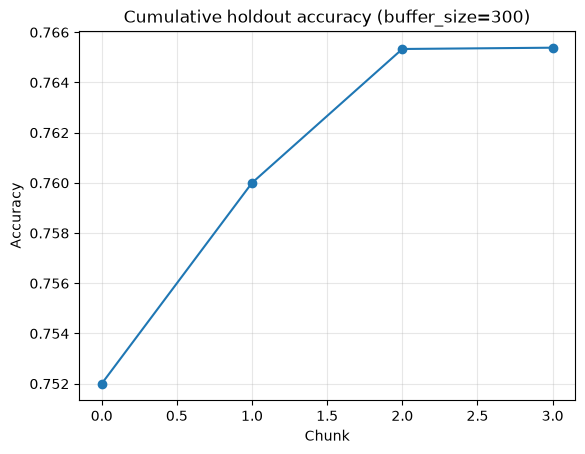

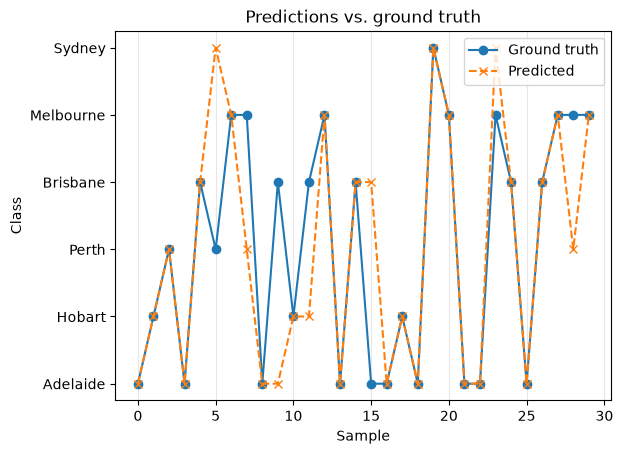

Latest holdout chunk — age, income, true label, predicted label:
[   31.   63118.75] Adelaide Adelaide
[   47.   39614.58] Hobart Hobart
[   49.   99294.43] Perth Perth
[   18.   53147.46] Adelaide Adelaide
[   53.   85308.41] Brisbane Brisbane
[    47.   116731.44] Perth Sydney
[   18.   75794.99] Melbourne Melbourne
[   45.   96875.68] Melbourne Perth
[   32.   64444.16] Adelaide Adelaide
[   32.   64797.14] Brisbane Adelaide


In [30]:
from numcompute_stream.visualise import compare_models, plot_metric_over_time, plot_predictions_vs_ground_truth

compare_models(
    small_chunk_accuracy,
    large_chunk_accuracy,
    labels=("buffer_size=300", "buffer_size=600"),
    show=True,
)
plot_metric_over_time(
    small_cumulative_accuracy,
    title="Cumulative holdout accuracy (buffer_size=300)",
    ylabel="Accuracy",
    show=True,
)
plot_predictions_vs_ground_truth(latest_y_true, latest_y_pred, show=True)

print("Latest holdout chunk — age, income, true label, predicted label:")
for features, actual, predicted in zip(latest_X[:10], latest_y_true[:10], latest_y_pred[:10]):
    print(features, actual, predicted)

## 4. Benchmark streaming updates and accuracy

Train fresh trees three times on the same ordered training chunks for each buffer size, then evaluate the same untouched holdout set. The table reports median wall-clock time for all `partial_fit` calls, the portion spent inside actual tree retraining (`fit`), the number of retrains, and rows left buffered without a final retrain. Timing excludes holdout prediction and StreamTrainer memory tracing. Durations vary by machine and load.

The second table compares plain-Python loop and NumPy cumulative accuracy on the same holdout prediction chunks; shorter chunks are weighted by their sample counts. Input conversion and model prediction are outside the timed region. The existing `python -m benchmark.run_benchmarks` runner covers additional batch loop-versus-NumPy cases.

In [31]:
from IPython.display import Markdown, display
from benchmark.stream_benchmark import benchmark_buffer_sizes, benchmark_chunk_accuracy
from numcompute.benchmarking import environment_info, format_table

benchmark_rows = benchmark_buffer_sizes(
    X_stream_train, y_stream_train, X_stream_test, y_stream_test,
    buffer_sizes=(300, 600), chunk_size=stream_chunk_size, max_depth=6, repeat=3,
)
lines = [
    "| Buffer size | Retrains | Pending rows | Update time (ms) | Retraining time (ms) | Holdout accuracy |",
    "|---:|---:|---:|---:|---:|---:|",
]
for row in benchmark_rows:
    lines.append(
        f"| {row['buffer_size']} | {row['retrain_count']} | {row['buffered_samples']} "
        f"| {row['update_seconds'] * 1000:.3f} | {row['retrain_seconds'] * 1000:.3f} "
        f"| {row['accuracy']:.3f} |"
    )
display(Markdown("\n".join(lines)))
print("Environment:", environment_info())

holdout_predictions = pipe_small_buffer.predict(X_stream_test)
accuracy_comparison = benchmark_chunk_accuracy(
    y_stream_test, holdout_predictions, chunk_size=stream_chunk_size, repeat=3,
)
display(Markdown(format_table([accuracy_comparison])))

| Buffer size | Retrains | Pending rows | Update time (ms) | Retraining time (ms) | Holdout accuracy |
|---:|---:|---:|---:|---:|---:|
| 300 | 3 | 245 | 23.186 | 23.076 | 0.765 |
| 600 | 2 | 245 | 18.539 | 18.447 | 0.759 |

Environment: {'python': '3.14.6', 'numpy': '2.5.1', 'os': 'macOS-26.6.2-arm64-arm-64bit-Mach-O', 'cpu': 'arm', 'cpu_count': '10'}


| Operation | NumCompute result | Baseline/result | Notes |
|---|---:|---:|---|
| chunked cumulative accuracy | 0.025 ms | 0.036 ms (1.4x) |  |